In [ ]:
from optiland import optic, physical_apertures
from optiland.psf import MMDFTPSF
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import differential_evolution
plt.rcParams['figure.figsize'] = (20,10)
import warnings
warnings.filterwarnings('ignore')
from poppy.zernike import zernike_basis
from nautilus import Sampler
from scipy.optimize import minimize

In [6]:
def decompose_psf(psf, nterms=10, basis=zernike_basis, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=0.0, **kwargs)
    basis_set = np.array(basis_set)
    psf_flat = psf.ravel()
    basis_flat = basis_set.reshape(nterms, -1)
    numerators = np.matmul(basis_flat, psf_flat)
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs

In [7]:
def hubble(WL=0.55,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    T = 3600
    #Hubble
    hubble = optic.Optic(name="Hubble")

    hubble.add_surface(index=0, radius=np.inf, thickness=np.inf)
    hubble.add_surface(index=1, thickness=4910.01016)

    # add physical aperture in primary mirror
    obscuration = physical_apertures.RadialAperture(r_max=1200, r_min=384)
    c1 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=0, offset_y=1000)
    c2 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=-707.15, offset_y=-707.15)
    c3 = physical_apertures.OffsetRadialAperture(r_max=75, r_min=0, offset_x=707.15, offset_y=-707.15)
    r1 = physical_apertures.RectangularAperture(x_min=-19, x_max=19, y_min=-1200, y_max=1200)
    r2 = physical_apertures.RectangularAperture(x_min=-1200, x_max=1200, y_min=-19, y_max=19)

    ap = obscuration - r1 - r2 -c1 - c2 - c3

    hubble.add_surface(
            index=2,
            radius=-11040.02286,
            thickness=-4910.01016,
            material="mirror",
            is_stop=True,
            conic=-1.001152,
            aperture=ap,
        )
    hubble.add_surface(
            index=3,
            radius=-1349.31166,
            thickness=6365.20955+sdz/K,
            dx=sdx/K,
            dy=sdy/K,
            rx=stx/T,
            ry=sty/T,
            material="mirror",
            conic=-1.483014,
        )
    hubble.add_surface(index=4, radius=-635.38227)

    hubble.set_aperture(aperture_type="EPD", value=2400)

    hubble.set_field_type(field_type="angle")
    hubble.add_field(y=0.)
    hubble.add_field(y=0.038)
    hubble.add_field(y=-0.038)

    hubble.add_wavelength(value=WL, is_primary=True)
    
    return hubble

In [ ]:
def genpsf(WL=0.55, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field =(0,0)):

    telescope = hubble(WL, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, grid_size=64)
    PSF = psf.psf[96:160,96:160]
    r = decompose_psf(PSF, nterms=dterms, basis=zernike_basis)

    return r

In [55]:
sdx_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdy_true = np.round(np.random.normal(loc=0,scale=50), 2)
sdz_true = np.round(np.random.normal(loc=0,scale=50), 2)
stx_true = np.round(np.random.normal(loc=0,scale=5), 2)
sty_true = np.round(np.random.normal(loc=0,scale=5), 2)

print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)
ct = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15)
ctf10 = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,0))
ctf01 = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(0,1))
ctf11 = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(1,1))
ctfm11 = genpsf(WL=0.55, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, stx=stx_true, sty=sty_true, dterms=15, field=(-1,-1))

-111.79 13.56 -39.29 -0.33 2.14


In [56]:
C = np.array([[ 2.8546e-02,  2.4201e-04, -3.1598e-04, -4.8934e-02, -3.2693e-04,
         -5.5986e-04, -1.0243e-03, -1.7370e-03, -4.9009e-05, -3.2011e-05,
          3.9497e-02,  9.0271e-04,  4.9170e-04,  1.0310e-04,  6.6334e-05],
        [ 2.4201e-04,  9.9158e-02, -1.7614e-03,  1.1474e-03,  2.0232e-03,
          2.0911e-03,  1.9443e-03, -9.4698e-02, -6.1838e-04,  1.3896e-05,
         -2.2020e-03, -2.8686e-03, -2.5514e-03,  1.9861e-05, -1.4131e-04],
        [-3.1598e-04, -1.7614e-03,  1.0099e-01,  2.1634e-03,  2.4404e-03,
         -2.2755e-03, -9.7984e-02,  1.9599e-03,  3.0645e-04,  2.1593e-04,
         -3.0290e-03,  2.9498e-03, -3.1703e-03, -7.1629e-05, -5.2912e-05],
        [-4.8934e-02,  1.1474e-03,  2.1634e-03,  1.0426e-01,  3.6707e-04,
          7.3733e-04,  8.9616e-04,  2.2155e-03,  3.6045e-05,  2.3623e-06,
         -9.9253e-02, -1.3523e-03, -5.8528e-04, -2.5646e-04, -9.3452e-05],
        [-3.2693e-04,  2.0232e-03,  2.4404e-03,  3.6707e-04,  3.4768e-02,
         -2.5238e-04, -1.7755e-03, -1.2087e-03,  1.0214e-03, -1.1731e-03,
         -4.0595e-05,  1.7350e-04, -3.5174e-02, -3.1900e-05,  1.4332e-04],
        [-5.5986e-04,  2.0911e-03, -2.2755e-03,  7.3733e-04, -2.5238e-04,
          3.5909e-02,  1.5078e-03, -1.4558e-03,  9.2375e-04,  1.1446e-03,
         -3.4590e-04, -3.7191e-02,  1.6025e-04,  2.9694e-04, -1.3420e-04],
        [-1.0243e-03,  1.9443e-03, -9.7984e-02,  8.9616e-04, -1.7755e-03,
          1.5078e-03,  1.1243e-01, -2.1993e-03, -1.7086e-04, -3.8854e-04,
          5.2096e-04, -2.7584e-03,  3.1177e-03,  7.1545e-05,  5.9634e-05],
        [-1.7370e-03, -9.4698e-02,  1.9599e-03,  2.2155e-03, -1.2087e-03,
         -1.4558e-03, -2.1993e-03,  1.0681e-01,  6.0168e-04, -8.2099e-05,
         -6.8326e-04,  2.7540e-03,  2.2908e-03, -3.5036e-05,  1.4671e-04],
        [-4.9009e-05, -6.1838e-04,  3.0645e-04,  3.6045e-05,  1.0214e-03,
          9.2375e-04, -1.7086e-04,  6.0168e-04,  9.0955e-03, -1.2108e-04,
          1.7585e-05, -7.1916e-04, -8.8275e-04, -3.6350e-04,  3.9637e-04],
        [-3.2011e-05,  1.3896e-05,  2.1593e-04,  2.3623e-06, -1.1731e-03,
          1.1446e-03, -3.8854e-04, -8.2099e-05, -1.2108e-04,  9.4166e-03,
          5.8236e-06, -1.0284e-03,  1.0278e-03,  3.9824e-04,  3.7200e-04],
        [ 3.9497e-02, -2.2020e-03, -3.0290e-03, -9.9253e-02, -4.0595e-05,
         -3.4590e-04,  5.2096e-04, -6.8326e-04,  1.7585e-05,  5.8236e-06,
          1.0623e-01,  6.7788e-04,  1.9345e-04,  2.4776e-04,  5.0283e-05],
        [ 9.0271e-04, -2.8686e-03,  2.9498e-03, -1.3523e-03,  1.7350e-04,
         -3.7191e-02, -2.7584e-03,  2.7540e-03, -7.1916e-04, -1.0284e-03,
          6.7788e-04,  4.3718e-02, -1.6952e-04, -2.9792e-04,  1.8890e-04],
        [ 4.9170e-04, -2.5514e-03, -3.1703e-03, -5.8528e-04, -3.5174e-02,
          1.6025e-04,  3.1177e-03,  2.2908e-03, -8.8275e-04,  1.0278e-03,
          1.9345e-04, -1.6952e-04,  4.0530e-02, -2.1973e-06, -1.8618e-04],
        [ 1.0310e-04,  1.9861e-05, -7.1629e-05, -2.5646e-04, -3.1900e-05,
          2.9694e-04,  7.1545e-05, -3.5036e-05, -3.6350e-04,  3.9824e-04,
          2.4776e-04, -2.9792e-04, -2.1973e-06,  1.0394e-03,  1.3562e-05],
        [ 6.6334e-05, -1.4131e-04, -5.2912e-05, -9.3452e-05,  1.4332e-04,
         -1.3420e-04,  5.9634e-05,  1.4671e-04,  3.9637e-04,  3.7200e-04,
          5.0283e-05,  1.8890e-04, -1.8618e-04,  1.3562e-05,  9.7441e-04]])

Cf10 = np.array([[ 2.4945e-02,  5.5907e-05,  2.2013e-05, -1.9460e-02, -1.5741e-05,
          1.5280e-04, -1.2587e-04, -3.1571e-04,  9.6522e-05,  1.7850e-05,
          1.0632e-02, -7.0540e-05,  1.2029e-04, -9.3313e-05,  1.9598e-06],
        [ 5.5907e-05,  2.3996e-02, -2.1325e-06,  2.7717e-04,  3.7157e-04,
          1.8872e-04,  8.5539e-05, -1.6377e-02,  8.3274e-05, -1.7354e-04,
         -3.0404e-04, -2.7258e-04, -4.3048e-04, -1.1947e-05,  4.1689e-05],
        [ 2.2013e-05, -2.1325e-06,  2.3874e-02,  3.5570e-04,  4.2710e-05,
         -7.6366e-05, -1.6284e-02,  8.0914e-05,  3.1241e-04,  2.7508e-05,
         -5.8860e-04,  2.1116e-04, -1.0021e-04,  1.1133e-06,  1.0627e-05],
        [-1.9460e-02,  2.7717e-04,  3.5570e-04,  2.1254e-02,  7.0886e-05,
         -1.5751e-04, -2.5117e-04,  3.3004e-04, -2.6359e-05, -3.1337e-05,
         -1.4969e-02,  1.7340e-04, -2.6436e-04,  2.1309e-05,  2.3419e-05],
        [-1.5741e-05,  3.7157e-04,  4.2710e-05,  7.0886e-05,  9.7964e-03,
          7.3727e-05,  1.2969e-04, -1.6488e-04,  1.5722e-04, -1.2762e-04,
         -9.6648e-05, -2.4686e-05, -7.3866e-03, -1.5237e-06,  1.8495e-05],
        [ 1.5280e-04,  1.8872e-04, -7.6366e-05, -1.5751e-04,  7.3727e-05,
          9.6668e-03, -1.3317e-05, -3.1149e-06,  2.2465e-04,  1.5856e-04,
          1.4499e-04, -7.5133e-03, -1.8298e-05,  7.0672e-05,  3.6428e-05],
        [-1.2587e-04,  8.5539e-05, -1.6284e-02, -2.5117e-04,  1.2969e-04,
         -1.3317e-05,  1.4379e-02, -2.4475e-04, -2.0311e-04,  1.1947e-05,
          5.4444e-04, -9.8490e-05, -3.5348e-05, -1.7714e-06, -2.1795e-05],
        [-3.1571e-04, -1.6377e-02,  8.0914e-05,  3.3004e-04, -1.6488e-04,
         -3.1149e-06, -2.4475e-04,  1.4504e-02, -2.1935e-05,  4.1911e-05,
         -2.7628e-04,  2.0022e-04,  2.8146e-04,  1.1860e-05, -1.8974e-05],
        [ 9.6522e-05,  8.3274e-05,  3.1241e-04, -2.6359e-05,  1.5722e-04,
          2.2465e-04, -2.0311e-04, -2.1935e-05,  2.5922e-03,  8.7900e-06,
          5.0412e-06, -1.6769e-04, -9.4764e-05, -7.9261e-05,  8.5826e-05],
        [ 1.7850e-05, -1.7354e-04,  2.7508e-05, -3.1337e-05, -1.2762e-04,
          1.5856e-04,  1.1947e-05,  4.1911e-05,  8.7900e-06,  2.6949e-03,
          2.6966e-05, -6.1401e-05,  9.9067e-05,  9.4053e-05,  8.7917e-05],
        [ 1.0632e-02, -3.0404e-04, -5.8860e-04, -1.4969e-02, -9.6648e-05,
          1.4499e-04,  5.4444e-04, -2.7628e-04,  5.0412e-06,  2.6966e-05,
          1.2765e-02, -2.3568e-04,  2.8904e-04,  1.1269e-05, -1.8960e-05],
        [-7.0540e-05, -2.7258e-04,  2.1116e-04,  1.7340e-04, -2.4686e-05,
         -7.5133e-03, -9.8490e-05,  2.0022e-04, -1.6769e-04, -6.1401e-05,
         -2.3568e-04,  6.8763e-03, -2.1215e-05, -7.0845e-05, -4.8677e-05],
        [ 1.2029e-04, -4.3048e-04, -1.0021e-04, -2.6436e-04, -7.3866e-03,
         -1.8298e-05, -3.5348e-05,  2.8146e-04, -9.4764e-05,  9.9067e-05,
          2.8904e-04, -2.1215e-05,  6.5824e-03, -1.3629e-05, -3.3258e-05],
        [-9.3313e-05, -1.1947e-05,  1.1133e-06,  2.1309e-05, -1.5237e-06,
          7.0672e-05, -1.7714e-06,  1.1860e-05, -7.9261e-05,  9.4053e-05,
          1.1269e-05, -7.0845e-05, -1.3629e-05,  2.3729e-04,  1.6122e-06],
        [ 1.9598e-06,  4.1689e-05,  1.0627e-05,  2.3419e-05,  1.8495e-05,
          3.6428e-05, -2.1795e-05, -1.8974e-05,  8.5826e-05,  8.7917e-05,
         -1.8960e-05, -4.8677e-05, -3.3258e-05,  1.6122e-06,  2.3884e-04]])
 
Cf01 = np.array([[ 2.5825e-02,  3.4759e-04,  6.9363e-04, -2.0007e-02,  2.7380e-04,
         -6.7619e-04, -7.4226e-04, -8.0018e-04,  5.9181e-05, -3.2758e-05,
          1.0474e-02,  6.5456e-04, -1.5349e-04, -4.3828e-05,  1.0945e-04],
        [ 3.4759e-04,  2.3967e-02,  3.0282e-04, -2.3198e-04,  5.7215e-04,
          2.3489e-04, -1.6278e-04, -1.6614e-02,  3.6699e-04, -4.1841e-04,
         -1.4701e-04, -3.4781e-04, -5.9959e-04, -2.2985e-05, -2.5307e-05],
        [ 6.9363e-04,  3.0282e-04,  2.5692e-02,  2.3044e-05,  1.3292e-04,
         -4.4587e-04, -1.7915e-02, -1.6773e-04, -4.9897e-05,  1.3882e-04,
         -4.7040e-04,  4.9822e-04, -4.6974e-04, -1.0655e-04,  1.5651e-06],
        [-2.0007e-02, -2.3198e-04,  2.3044e-05,  2.1298e-02, -6.7113e-05,
          3.2339e-04,  2.3853e-04,  7.4150e-04, -3.5852e-05,  9.4702e-05,
         -1.4339e-02, -2.4960e-04, -1.1907e-04, -8.2576e-06, -7.9877e-05],
        [ 2.7380e-04,  5.7215e-04,  1.3292e-04, -6.7113e-05,  1.0019e-02,
          3.0701e-04, -2.0375e-04, -3.0650e-04,  1.6075e-04, -3.9945e-04,
         -9.8362e-05, -3.2035e-04, -7.6757e-03, -2.9148e-05, -1.8049e-05],
        [-6.7619e-04,  2.3489e-04, -4.4587e-04,  3.2339e-04,  3.0701e-04,
          1.0038e-02,  2.0164e-04, -8.1875e-05,  1.7708e-04,  1.3640e-04,
          1.4224e-05, -7.9750e-03, -3.1115e-04, -4.8107e-07,  1.6098e-05],
        [-7.4226e-04, -1.6278e-04, -1.7915e-02,  2.3853e-04, -2.0375e-04,
          2.0164e-04,  1.5854e-02, -3.7186e-05,  1.0873e-04, -1.4107e-04,
          3.1591e-04, -3.8227e-04,  5.9492e-04,  9.4570e-05,  1.9240e-05],
        [-8.0018e-04, -1.6614e-02, -1.6773e-04,  7.4150e-04, -3.0650e-04,
         -8.1875e-05, -3.7186e-05,  1.4963e-02, -3.0300e-04,  2.3171e-04,
         -1.3178e-04,  2.5493e-04,  4.1526e-04,  2.3822e-05,  2.8102e-05],
        [ 5.9181e-05,  3.6699e-04, -4.9897e-05, -3.5852e-05,  1.6075e-04,
          1.7708e-04,  1.0873e-04, -3.0300e-04,  2.7117e-03, -2.6473e-05,
         -1.1865e-05, -7.5782e-05, -1.3080e-04, -1.0025e-04,  7.1173e-05],
        [-3.2758e-05, -4.1841e-04,  1.3882e-04,  9.4702e-05, -3.9945e-04,
          1.3640e-04, -1.4107e-04,  2.3171e-04, -2.6473e-05,  2.7120e-03,
         -6.8353e-05, -1.2439e-04,  3.2797e-04,  9.1049e-05,  1.2585e-04],
        [ 1.0474e-02, -1.4701e-04, -4.7040e-04, -1.4339e-02, -9.8362e-05,
          1.4224e-05,  3.1591e-04, -1.3178e-04, -1.1865e-05, -6.8353e-05,
          1.1805e-02, -1.7040e-04,  2.5451e-04,  2.5833e-05,  3.1106e-05],
        [ 6.5456e-04, -3.4781e-04,  4.9822e-04, -2.4960e-04, -3.2035e-04,
         -7.9750e-03, -3.8227e-04,  2.5493e-04, -7.5782e-05, -1.2439e-04,
         -1.7040e-04,  7.4493e-03,  3.5640e-04, -1.0678e-05, -5.8953e-06],
        [-1.5349e-04, -5.9959e-04, -4.6974e-04, -1.1907e-04, -7.6757e-03,
         -3.1115e-04,  5.9492e-04,  4.1526e-04, -1.3080e-04,  3.2797e-04,
          2.5451e-04,  3.5640e-04,  6.9483e-03,  3.3746e-05,  1.6797e-05],
        [-4.3828e-05, -2.2985e-05, -1.0655e-04, -8.2576e-06, -2.9148e-05,
         -4.8107e-07,  9.4570e-05,  2.3822e-05, -1.0025e-04,  9.1049e-05,
          2.5833e-05, -1.0678e-05,  3.3746e-05,  2.4574e-04,  2.0257e-06],
        [ 1.0945e-04, -2.5307e-05,  1.5651e-06, -7.9877e-05, -1.8049e-05,
          1.6098e-05,  1.9240e-05,  2.8102e-05,  7.1173e-05,  1.2585e-04,
          3.1106e-05, -5.8953e-06,  1.6797e-05,  2.0257e-06,  2.4386e-04]])

Cf11 = np.array([[ 2.5151e-02,  4.9206e-04,  3.8755e-05, -1.9912e-02,  3.1575e-04,
          5.8295e-04, -5.8781e-04, -8.4987e-04, -7.8606e-05,  1.5631e-04,
          1.1056e-02, -8.5277e-04, -2.1693e-04,  7.8328e-06, -6.5717e-05],
        [ 4.9206e-04,  2.4519e-02,  4.8069e-04, -1.1136e-04, -6.7219e-05,
          6.3964e-04, -2.9173e-04, -1.7175e-02,  7.1050e-06,  2.7220e-04,
         -1.5810e-04, -7.3271e-04, -9.5070e-05,  5.3248e-05, -2.9390e-05],
        [ 3.8755e-05,  4.8069e-04,  2.3523e-02, -1.1252e-06,  1.9711e-04,
         -2.8605e-04, -1.5774e-02, -2.9192e-04,  5.8739e-05, -2.9267e-04,
         -5.3134e-06,  2.9853e-04, -1.7989e-04,  1.8308e-05,  5.0888e-05],
        [-1.9912e-02, -1.1136e-04, -1.1252e-06,  2.1977e-02, -1.5223e-04,
         -6.8314e-04,  8.4493e-04,  7.8184e-04, -3.9015e-06, -1.4511e-04,
         -1.5645e-02,  1.0052e-03,  2.1690e-05, -1.9532e-05,  4.8950e-05],
        [ 3.1575e-04, -6.7219e-05,  1.9711e-04, -1.5223e-04,  9.3243e-03,
         -1.7050e-04,  2.9706e-05,  9.6948e-05,  3.0008e-04, -1.5924e-04,
         -1.9766e-05,  1.6032e-04, -7.0334e-03, -2.6994e-05,  4.8755e-05],
        [ 5.8295e-04,  6.3964e-04, -2.8605e-04, -6.8314e-04, -1.7050e-04,
          1.0059e-02,  5.9364e-05, -4.3987e-04,  1.4240e-04,  2.0636e-04,
          3.7220e-04, -7.8589e-03,  1.5636e-04,  7.6944e-05, -6.7041e-06],
        [-5.8781e-04, -2.9173e-04, -1.5774e-02,  8.4493e-04,  2.9706e-05,
          5.9364e-05,  1.3669e-02,  8.8541e-05, -1.2132e-04,  2.3527e-04,
         -5.6448e-04, -2.2229e-04,  7.7750e-05,  8.1372e-06, -1.6901e-05],
        [-8.4987e-04, -1.7175e-02, -2.9192e-04,  7.8184e-04,  9.6948e-05,
         -4.3987e-04,  8.8541e-05,  1.5561e-02, -4.2270e-06, -3.4508e-04,
         -3.3953e-04,  7.1975e-04,  2.1552e-04, -6.6317e-05,  8.5131e-06],
        [-7.8606e-05,  7.1050e-06,  5.8739e-05, -3.9015e-06,  3.0008e-04,
          1.4240e-04, -1.2132e-04, -4.2270e-06,  2.5653e-03, -2.2833e-05,
          3.5682e-05, -5.7887e-05, -1.7743e-04, -8.1880e-05,  8.9068e-05],
        [ 1.5631e-04,  2.7220e-04, -2.9267e-04, -1.4511e-04, -1.5924e-04,
          2.0636e-04,  2.3527e-04, -3.4508e-04, -2.2833e-05,  2.6215e-03,
          5.8182e-05, -1.7683e-04,  1.0235e-04,  1.1936e-04,  9.4002e-05],
        [ 1.1056e-02, -1.5810e-04, -5.3134e-06, -1.5645e-02, -1.9766e-05,
          3.7220e-04, -5.6448e-04, -3.3953e-04,  3.5682e-05,  5.8182e-05,
          1.3453e-02, -6.0213e-04,  9.0821e-05,  1.5228e-05, -1.9450e-05],
        [-8.5277e-04, -7.3271e-04,  2.9853e-04,  1.0052e-03,  1.6032e-04,
         -7.8589e-03, -2.2229e-04,  7.1975e-04, -5.7887e-05, -1.7683e-04,
         -6.0213e-04,  7.2330e-03, -1.7027e-04, -1.0261e-04, -9.0021e-06],
        [-2.1693e-04, -9.5070e-05, -1.7989e-04,  2.1690e-05, -7.0334e-03,
          1.5636e-04,  7.7750e-05,  2.1552e-04, -1.7743e-04,  1.0235e-04,
          9.0821e-05, -1.7027e-04,  6.2815e-03,  2.4826e-05, -7.5455e-05],
        [ 7.8328e-06,  5.3248e-05,  1.8308e-05, -1.9532e-05, -2.6994e-05,
          7.6944e-05,  8.1372e-06, -6.6317e-05, -8.1880e-05,  1.1936e-04,
          1.5228e-05, -1.0261e-04,  2.4826e-05,  2.2830e-04, -1.1233e-06],
        [-6.5717e-05, -2.9390e-05,  5.0888e-05,  4.8950e-05,  4.8755e-05,
         -6.7041e-06, -1.6901e-05,  8.5131e-06,  8.9068e-05,  9.4002e-05,
         -1.9450e-05, -9.0021e-06, -7.5455e-05, -1.1233e-06,  2.1837e-04]])

Cfm11 = np.array([[ 2.6752e-02, -1.9947e-04,  7.0809e-04, -2.1946e-02, -2.4384e-04,
          1.8911e-04, -9.0360e-04,  4.3173e-05, -7.0769e-05,  5.7945e-06,
          1.2685e-02,  2.9137e-05,  2.1291e-04, -1.0182e-04,  5.3739e-05],
        [-1.9947e-04,  2.4932e-02, -1.7666e-04,  4.7303e-04,  2.6662e-04,
          1.2903e-04,  1.8245e-04, -1.7305e-02, -6.2714e-05, -1.2105e-04,
         -5.2042e-04, -2.5128e-04, -4.4906e-04,  6.1654e-08, -5.0010e-05],
        [ 7.0809e-04, -1.7666e-04,  2.4508e-02, -2.2469e-04,  9.4201e-05,
         -7.4690e-04, -1.7263e-02,  1.7797e-04,  3.6854e-04,  5.8813e-05,
         -2.4897e-04,  7.9732e-04, -1.7347e-04, -1.9406e-05,  9.3736e-06],
        [-2.1946e-02,  4.7303e-04, -2.2469e-04,  2.4912e-02,  1.1018e-04,
         -2.7991e-05,  6.3392e-04, -1.8567e-04,  1.6868e-05, -2.9966e-05,
         -1.8243e-02, -1.8101e-04, -9.1670e-05,  4.2642e-05, -7.1119e-05],
        [-2.4384e-04,  2.6662e-04,  9.4201e-05,  1.1018e-04,  9.9653e-03,
         -2.0368e-05,  7.4579e-05, -1.6237e-04,  1.6638e-04, -3.2553e-04,
          1.4033e-05, -5.2952e-05, -7.5995e-03,  4.4476e-05,  5.7161e-05],
        [ 1.8911e-04,  1.2903e-04, -7.4690e-04, -2.7991e-05, -2.0368e-05,
          9.8439e-03,  4.4907e-04,  4.5524e-06,  1.7828e-04,  1.2760e-04,
         -3.5181e-05, -7.7699e-03, -5.4251e-05,  2.6533e-05, -6.9359e-07],
        [-9.0360e-04,  1.8245e-04, -1.7263e-02,  6.3392e-04,  7.4579e-05,
          4.4907e-04,  1.5861e-02, -1.8225e-04, -2.0576e-04, -1.0861e-04,
         -9.1867e-05, -5.7030e-04,  9.4402e-06, -7.2545e-06, -7.4759e-06],
        [ 4.3173e-05, -1.7305e-02,  1.7797e-04, -1.8567e-04, -1.6237e-04,
          4.5524e-06, -1.8225e-04,  1.5463e-02, -1.7208e-05,  2.2339e-05,
          2.9242e-04,  1.6903e-04,  4.0165e-04, -1.7950e-05,  1.9230e-05],
        [-7.0769e-05, -6.2714e-05,  3.6854e-04,  1.6868e-05,  1.6638e-04,
          1.7828e-04, -2.0576e-04, -1.7208e-05,  2.6907e-03,  4.5380e-05,
          2.0949e-05, -1.7033e-04, -9.3353e-05, -1.0367e-04,  6.7823e-05],
        [ 5.7945e-06, -1.2105e-04,  5.8813e-05, -2.9966e-05, -3.2553e-04,
          1.2760e-04, -1.0861e-04,  2.2339e-05,  4.5380e-05,  2.6264e-03,
          2.7234e-05, -9.2802e-05,  2.2235e-04,  9.1897e-05,  7.3349e-05],
        [ 1.2685e-02, -5.2042e-04, -2.4897e-04, -1.8243e-02,  1.4033e-05,
         -3.5181e-05, -9.1867e-05,  2.9242e-04,  2.0949e-05,  2.7234e-05,
          1.5928e-02,  1.4878e-04, -2.9786e-05, -9.5578e-06,  4.0115e-05],
        [ 2.9137e-05, -2.5128e-04,  7.9732e-04, -1.8101e-04, -5.2952e-05,
         -7.7699e-03, -5.7030e-04,  1.6903e-04, -1.7033e-04, -9.2802e-05,
          1.4878e-04,  7.2164e-03,  1.4200e-04, -3.1485e-05, -1.5677e-05],
        [ 2.1291e-04, -4.4906e-04, -1.7347e-04, -9.1670e-05, -7.5995e-03,
         -5.4251e-05,  9.4402e-06,  4.0165e-04, -9.3353e-05,  2.2235e-04,
         -2.9786e-05,  1.4200e-04,  6.8785e-03, -4.6427e-05, -5.4725e-05],
        [-1.0182e-04,  6.1654e-08, -1.9406e-05,  4.2642e-05,  4.4476e-05,
          2.6533e-05, -7.2545e-06, -1.7950e-05, -1.0367e-04,  9.1897e-05,
         -9.5578e-06, -3.1485e-05, -4.6427e-05,  2.4248e-04, -3.2656e-06],
        [ 5.3739e-05, -5.0010e-05,  9.3736e-06, -7.1119e-05,  5.7161e-05,
         -6.9359e-07, -7.4759e-06,  1.9230e-05,  6.7823e-05,  7.3349e-05,
          4.0115e-05, -1.5677e-05, -5.4725e-05, -3.2656e-06,  2.2501e-04]])

Cinv = np.linalg.inv(C)  # precision matrix
Cf10inv = np.linalg.inv(Cf10)
Cf01inv = np.linalg.inv(Cf01)
Cf11inv = np.linalg.inv(Cf11)
Cfm11inv = np.linalg.inv(Cfm11)
lnorm = -0.5 * (np.log(np.array(2*np.pi)) * 4 + np.log(np.linalg.det(C)))  # ln(normalization)
lnormf10 = -0.5 * (np.log(np.array(2*np.pi)) * 4 + np.log(np.linalg.det(Cf10))) 
lnormf01 = -0.5 * (np.log(np.array(2*np.pi)) * 4 + np.log(np.linalg.det(Cf01))) 
lnormf11 = -0.5 * (np.log(np.array(2*np.pi)) * 4 + np.log(np.linalg.det(Cf11))) 
lnormfm11 = -0.5 * (np.log(np.array(2*np.pi)) * 4 + np.log(np.linalg.det(Cfm11))) 

# log-likelihood
def loglike(theta):
    lsdx,lsdy,lsdz,lstx,lsty = theta
    ## PSF
    c = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=15)
    cf01 = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=15, field=(1,0))
    cf10 = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=15, field=(0,1))
    cf11 = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=15, field=(1,1))
    cfm11 = genpsf(WL=0.55, sdx=lsdx, sdy=lsdy, sdz=lsdz, stx=lstx, sty=lsty, dterms=15, field=(-1,-1))

    return -0.5 * np.matmul(np.array(c-ct), np.matmul(Cinv, np.array(c-ct))) + lnorm -0.5 * np.matmul(np.array(cf01-ctf01), np.matmul(Cf10inv, np.array(cf01-ctf01))) + lnormf01 -0.5 * np.matmul(np.array(cf10-ctf10), np.matmul(Cf10inv, np.array(cf10-ctf10))) + lnormf10 -0.5 * np.matmul(np.array(cf11-ctf11), np.matmul(Cf11inv, np.array(cf11-ctf11))) + lnormf11 -0.5 * np.matmul(np.array(cfm11-ctfm11), np.matmul(Cfm11inv, np.array(cfm11-ctfm11))) + lnormfm11
# prior transform
def ptform(utheta):

    usx,usy,usz,ustx,usty = utheta

    xsx =  np.round((200. * (2. * usx - 1.)), decimals=2)
    xsy =  np.round((200. * (2. * usy - 1.)), decimals=2)
    xsz =  np.round((200. * (2. * usz - 1.)), decimals=2)
    xstx =  np.round((10. * (2. * ustx - 1.)), decimals=2)
    xsty =  np.round((10. * (2. * usty - 1.)), decimals=2)

    return xsx,xsy,xsz,xstx,xsty

In [57]:
loglike([sdx_true, sdy_true, sdz_true, stx_true, sty_true])

np.float64(186.20370385992874)

In [58]:
sampler = Sampler(ptform, loglike, n_dim=5)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 20     | 1        | 4        | 43700    | N/A    | 11307 | +176.58  


np.True_

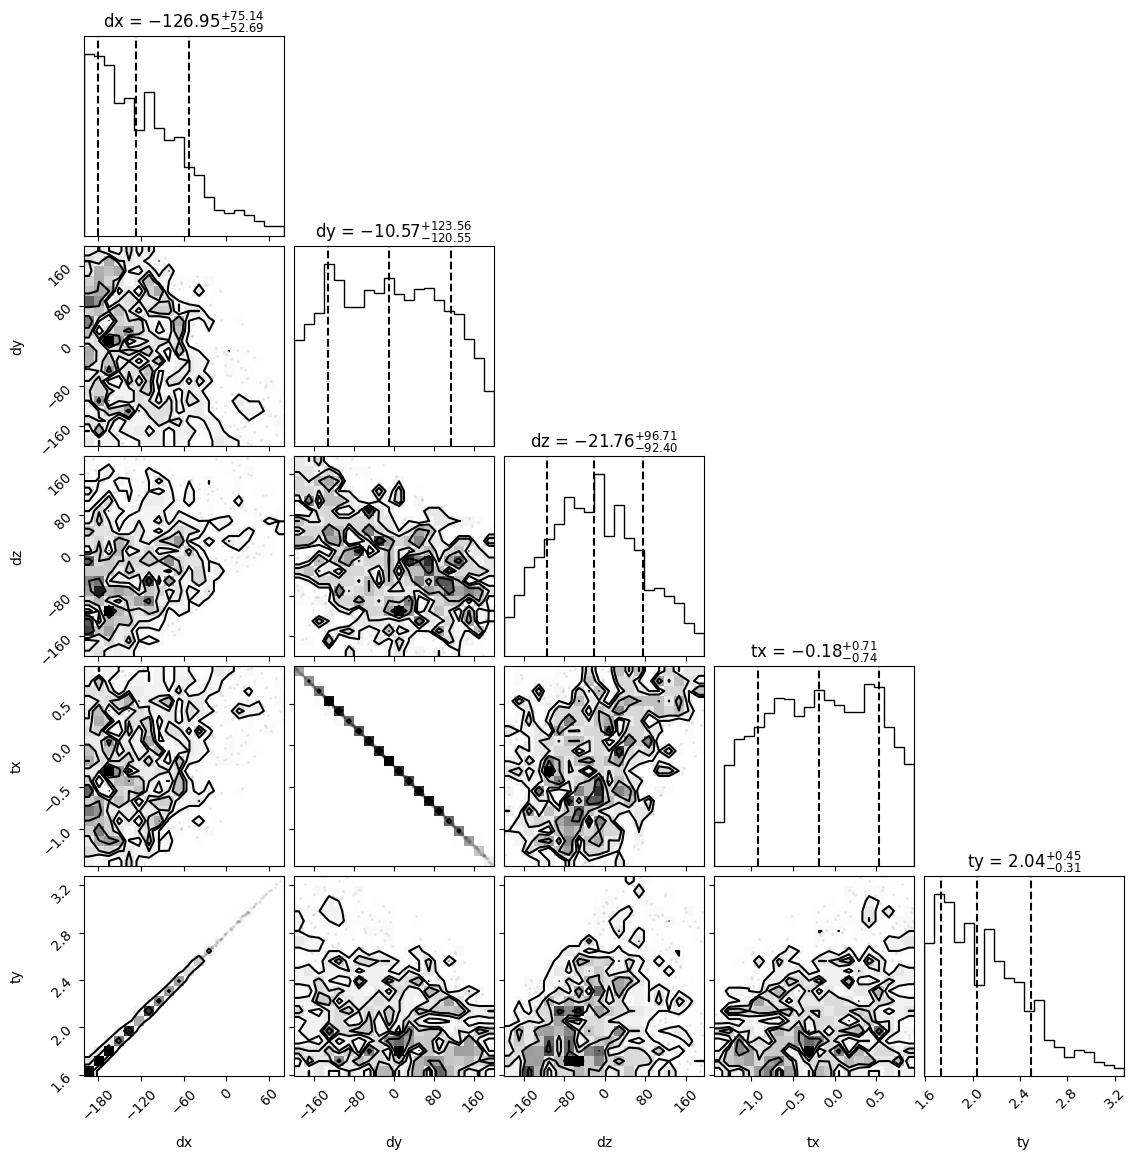

In [79]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points[-1000:], weights=np.exp(log_w)[-1000:], labels=['dx', 'dy', 'dz', 'tx', 'ty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

In [60]:
x0 = [np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,4], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf')]

In [61]:
x0

[array(-128.35), array(-27.92), array(-8.99), array(-0.08), array(2.03)]

In [62]:
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

-111.79 13.56 -39.29 -0.33 2.14


In [63]:
def lstep(t):
    return np.sum(np.array(ct - genpsf(WL=0.55, sdx=t[0], sdy=t[1], sdz=t[2], stx=t[3], sty=t[4], dterms=15))**2)

In [64]:
bounds = [(np.quantile(points[-100:,0], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,4], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,4], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [65]:
bounds

[(array(-198.68), array(31.34)),
 (array(-190.97), array(181.31)),
 (array(-188.13), array(174.77)),
 (array(-1.31), array(0.88)),
 (array(1.62), array(2.98))]

In [ ]:
def my_callback(intermediate_result):
    # intermediate_result is an OptimizeResult object
    best_x = intermediate_result.x
    current_min = intermediate_result.fun
    print(f"Current best: {current_min} at {best_x}")

In [ ]:
result = differential_evolution(lstep, bounds, callback = my_callback, x0 = x0)
print(result.x)
print(sdx_true, sdy_true, sdz_true, stx_true, sty_true)

differential_evolution step 1: f(x)= 2.9355157569510827e-05
differential_evolution step 2: f(x)= 2.9355157569510827e-05
differential_evolution step 3: f(x)= 2.9355157569510827e-05
differential_evolution step 4: f(x)= 2.9355157569510827e-05
differential_evolution step 5: f(x)= 2.9355157569510827e-05
differential_evolution step 6: f(x)= 2.9355157569510827e-05
differential_evolution step 7: f(x)= 2.81649325177112e-05
differential_evolution step 8: f(x)= 1.990515065151182e-05
differential_evolution step 9: f(x)= 1.990515065151182e-05
differential_evolution step 10: f(x)= 1.990515065151182e-05
differential_evolution step 11: f(x)= 1.990515065151182e-05
differential_evolution step 12: f(x)= 1.990515065151182e-05
differential_evolution step 13: f(x)= 5.113498914879347e-06
differential_evolution step 14: f(x)= 5.113498914879347e-06
differential_evolution step 15: f(x)= 5.113498914879347e-06
differential_evolution step 16: f(x)= 3.836723414874816e-06
differential_evolution step 17: f(x)= 2.9428